In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, pearsonr, qmc
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RNG_SEED = 42
np.random.seed(RNG_SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {RNG_SEED}")
print()


Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



Dataset: n=46 observations, d=8 input dimensions
Input range per dimension  : min=[0.009 0.003 0.023 0.009 0.01  0.022 0.036 0.042]
                             max=[0.986 0.974 0.999 0.903 1.    0.99  0.993 0.989]
Output range: [5.592, 9.997], mean=8.078, std=1.120



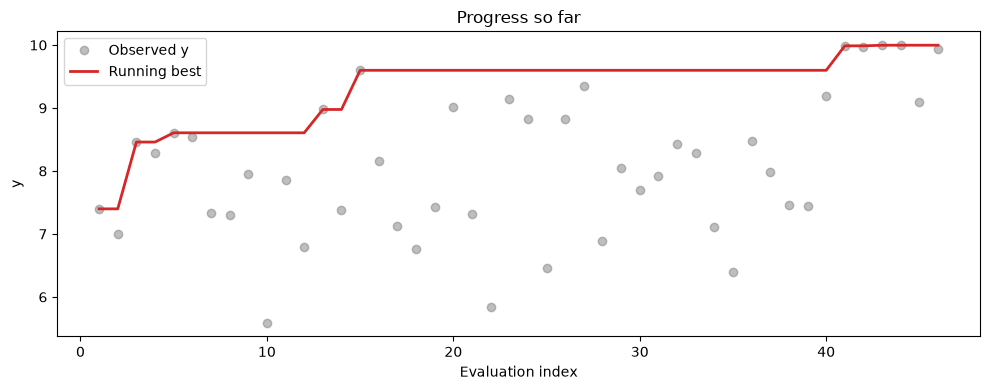

In [2]:
# --------------------------------------------------------------------- #
# DATA
# --------------------------------------------------------------------- #
X = np.load('..\Function_8_Data\Week_7_Data/F8_Week_7_inputs.npy')
y = np.load('..\Function_8_Data\Week_7_Data/F8_Week_7_outputs.npy')

n, d = X.shape
print(f"Dataset: n={n} observations, d={d} input dimensions")
print(f"Input range per dimension  : min={X.min(axis=0).round(3)}")
print(f"                             max={X.max(axis=0).round(3)}")
print(f"Output range: [{y.min():.3f}, {y.max():.3f}], mean={y.mean():.3f}, std={y.std():.3f}\n")


#--------------------------------------------------------------------------
# Optimisation history: Progress so far
#--------------------------------------------------------------------------
plt.figure(figsize=(10, 4))
running_best = np.maximum.accumulate(y)
plt.plot(np.arange(1, n + 1), y, "o", color="tab:gray", alpha=0.5, label="Observed y")
plt.plot(np.arange(1, n + 1), running_best, "-", color="tab:red", lw=2, label="Running best")
plt.xlabel("Evaluation index")
plt.ylabel("y")
plt.title("Progress so far")
plt.legend()
plt.tight_layout()

Skewness of y: -0.018 (close to 0 -> no log/Box-Cox transform needed)



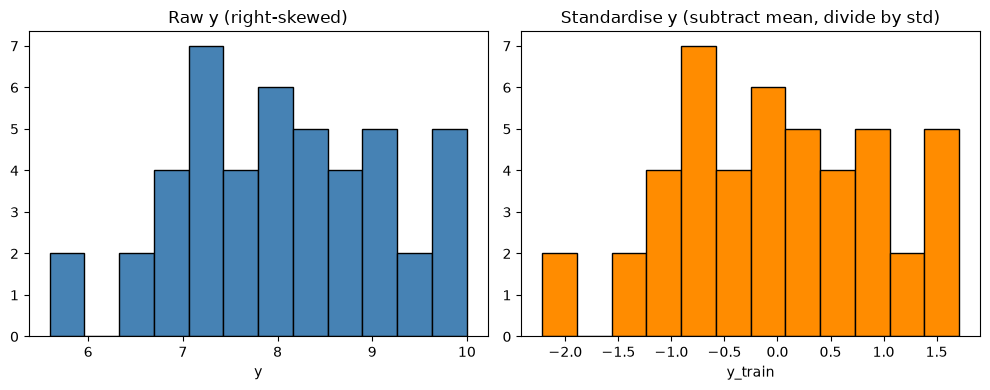

In [3]:
# --------------------------------------------------------------------- #
# DATA TRANSFORMATION
# --------------------------------------------------------------------- #
# INPUTS
# ------
# All 8 columns already lie in (a numerical approximation of) [0, 1].
X_train = X.copy()
bounds = np.array([[0.0, 1.0]] * d)  # search domain for the acquisition optimiser

# OUTPUTS
# -------
# y ranges from ~5.6 to ~10.0 with a non-zero mean (~7.9) and no obvious
# skew/heavy tail (a quick skewness check below confirms this). 
# Standardise y (subtract mean, divide by std) before fitting.
# Convert GP predictions back to the original scale for reporting/plotting.

from scipy.stats import skew
print(f"Skewness of y: {skew(y):.3f} (close to 0 -> no log/Box-Cox transform needed)\n")

y_mean, y_std = y.mean(), y.std()
y_train = (y - y_mean) / y_std


def unstandardise(mu_s, sigma_s):
    """Map standardised GP posterior mean/std back to the original y scale."""
    return mu_s * y_std + y_mean, sigma_s * y_std

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0].set_title("Raw y (right-skewed)")
axes[0].set_xlabel("y")
axes[1].hist(y_train, bins=12, color="darkorange", edgecolor="k")
axes[1].set_title("Standardise y (subtract mean, divide by std)")
axes[1].set_xlabel("y_train")
plt.tight_layout()



In [4]:
# --------------------------------------------------------------------- #
# 3. ARD vs Isotropic
# --------------------------------------------------------------------- #
print("Marginal (linear) correlation of each input dimension with y:")
corrs = []
for j in range(d):
    r, _ = pearsonr(X_train[:, j], y)
    corrs.append(r)
    print(f"  x{j+1}: r = {r:+.3f}")
corrs = np.array(corrs)
print()


Marginal (linear) correlation of each input dimension with y:
  x1: r = -0.712
  x2: r = -0.328
  x3: r = -0.713
  x4: r = -0.230
  x5: r = +0.078
  x6: r = +0.068
  x7: r = -0.484
  x8: r = +0.141



ARD model      : 8.44**2 * Matern(length_scale=[5.94, 8.41, 4.86, 8.06, 11.9, 8.67, 6.1, 100], nu=2.5) + WhiteKernel(noise_level=1e-06)
  log-marginal-likelihood = 19.362
Isotropic model: 5.06**2 * Matern(length_scale=4.43, nu=2.5) + WhiteKernel(noise_level=1e-06)
  log-marginal-likelihood = -5.954

-> Selected model: ARD (higher log-marginal-likelihood = better evidence fit)

Fitted ARD length-scales (smaller = objective varies faster along that axis):
  x1: length_scale = 5.944
  x2: length_scale = 8.414
  x3: length_scale = 4.862
  x4: length_scale = 8.065
  x5: length_scale = 11.870
  x6: length_scale = 8.666
  x7: length_scale = 6.102
  x8: length_scale = 100.000
Signal variance (amplitude^2): 71.273
Noise variance               : 1.000e-06



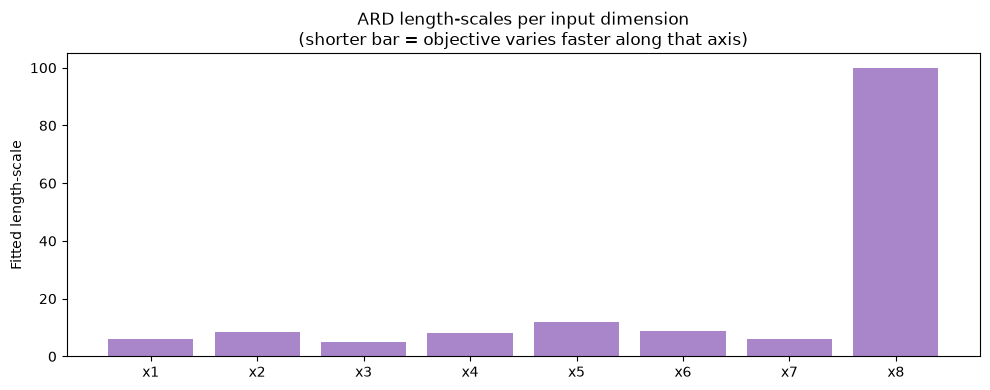

In [5]:
# --------------------------------------------------------------------- #
# SURROGATE MODEL: Gaussian Process, Matern-5/2 kernel
# --------------------------------------------------------------------- #

# We fit BOTH an ARD model and an isotropic model below and compare
# their log-marginal-likelihood (LML) to make the choice data-driven
# rather than asserted.

N_RESTARTS = 15
LENGTH_SCALE_BOUNDS = (1e-2, 1e2)
NOISE_BOUNDS = (1e-6, 1e-1)
JITTER = 1e-8  # small fixed diagonal jitter for numerical conditioning

kernel_ard = (
    ConstantKernel(1.0, (1e-2, 1e2))
    * Matern(length_scale=np.ones(d), length_scale_bounds=LENGTH_SCALE_BOUNDS, nu=2.5)
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=NOISE_BOUNDS)
)
kernel_iso = (
    ConstantKernel(1.0, (1e-2, 1e2))
    * Matern(length_scale=1.0, length_scale_bounds=LENGTH_SCALE_BOUNDS, nu=2.5)
    + WhiteKernel(noise_level=1e-3, noise_level_bounds=NOISE_BOUNDS)
)

gp_ard = GaussianProcessRegressor(
    kernel=kernel_ard, alpha=JITTER, n_restarts_optimizer=N_RESTARTS,
    normalize_y=False, random_state=RNG_SEED
)
gp_iso = GaussianProcessRegressor(
    kernel=kernel_iso, alpha=JITTER, n_restarts_optimizer=N_RESTARTS,
    normalize_y=False, random_state=RNG_SEED
)

gp_ard.fit(X_train, y_train)
gp_iso.fit(X_train, y_train)

lml_ard = gp_ard.log_marginal_likelihood(gp_ard.kernel_.theta)
lml_iso = gp_iso.log_marginal_likelihood(gp_iso.kernel_.theta)

print(f"ARD model      : {gp_ard.kernel_}")
print(f"  log-marginal-likelihood = {lml_ard:.3f}")
print(f"Isotropic model: {gp_iso.kernel_}")
print(f"  log-marginal-likelihood = {lml_iso:.3f}\n")

use_ard = lml_ard > lml_iso
gp = gp_ard if use_ard else gp_iso
print(f"-> Selected model: {'ARD' if use_ard else 'Isotropic'} "
      f"(higher log-marginal-likelihood = better evidence fit)\n")


matern_ard_fitted = gp_ard.kernel_.k1.k2  # Matern component of ARD kernel
length_scales = np.atleast_1d(matern_ard_fitted.length_scale)
signal_var = gp_ard.kernel_.k1.k1.constant_value
noise_level = gp_ard.kernel_.k2.noise_level
print("Fitted ARD length-scales (smaller = objective varies faster along that axis):")
for j in range(d):
    print(f"  x{j+1}: length_scale = {length_scales[j]:.3f}")
print(f"Signal variance (amplitude^2): {signal_var:.3f}")
print(f"Noise variance               : {noise_level:.3e}\n")

plt.figure(figsize=(10, 4))
dims = [f"x{j+1}" for j in range(d)]
bars = plt.bar(dims, length_scales, color="tab:purple", alpha=0.8)
plt.ylabel("Fitted length-scale")
plt.title("ARD length-scales per input dimension\n(shorter bar = objective varies faster along that axis)")
plt.tick_params(axis="x", rotation=0)
plt.tight_layout()

Leave-one-out CV: R^2 = 0.999, RMSE = 0.040



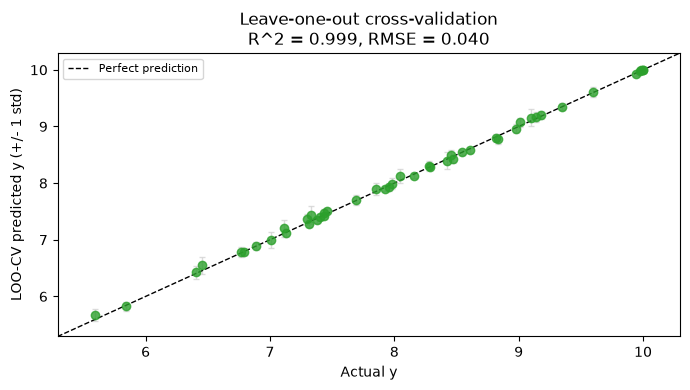

In [6]:
# --------------------------------------------------------------------- #
# MODEL CHECK: leave-one-out cross-validated predictions
# --------------------------------------------------------------------- #

loo_pred = np.zeros(n)
loo_std = np.zeros(n)
for i in range(n):
    mask = np.ones(n, dtype=bool)
    mask[i] = False
    gp_loo = GaussianProcessRegressor(
        kernel=gp.kernel_, alpha=JITTER, optimizer=None,  # reuse already-fitted hyperparameters
        normalize_y=False, random_state=RNG_SEED
    )
    gp_loo.fit(X_train[mask], y_train[mask])
    mu_s, std_s = gp_loo.predict(X_train[i:i+1], return_std=True)
    mu, std = unstandardise(mu_s, std_s)
    loo_pred[i] = mu[0]
    loo_std[i] = std[0]

ss_res = np.sum((y - loo_pred) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
loo_r2 = 1 - ss_res / ss_tot
rmse = np.sqrt(np.mean((y - loo_pred) ** 2))
print(f"Leave-one-out CV: R^2 = {loo_r2:.3f}, RMSE = {rmse:.3f}\n")

# (c) Leave-one-out predicted vs actual.
plt.figure(figsize=(7, 4))
plt.errorbar(y, loo_pred, yerr=loo_std, fmt="o", ecolor="lightgray",
            elinewidth=1, capsize=2, color="tab:green", alpha=0.8)
lims = [min(y.min(), loo_pred.min()) - 0.3, max(y.max(), loo_pred.max()) + 0.3]
plt.plot(lims, lims, "k--", lw=1, label="Perfect prediction")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Actual y")
plt.ylabel("LOO-CV predicted y (+/- 1 std)")
plt.title(f"Leave-one-out cross-validation\nR^2 = {loo_r2:.3f}, RMSE = {rmse:.3f}")
plt.legend(fontsize=8)
plt.tight_layout()

In [7]:
# --------------------------------------------------------------------- #
# ACQUISITION FUNCTION: Expected Improvement (EI)
# --------------------------------------------------------------------- #
# EI naturally accounts for both the predicted mean AND the
# uncertainty, balances exploration/exploitation without needing a
# kernel/units-dependent constant.
#
# We additionally plot UCB alongside EI purely as a diagnostic
# comparison since it's useful to check that both acquisitions 
# agree on the promising region.

XI = 0.01
f_best_std = y_train.max()  # incumbent in standardised units (maximisation)

def expected_improvement(Xq, gp, f_best, xi=XI):
    mu, sigma = gp.predict(Xq, return_std=True)
    sigma = np.maximum(sigma, 1e-9) 
    imp = mu - f_best - xi
    z = imp / sigma
    from scipy.stats import norm
    ei = imp * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

def upper_confidence_bound(Xq, gp, kappa=2.0):
    mu, sigma = gp.predict(Xq, return_std=True)
    return mu + kappa * sigma


NEXT SUGGESTED QUERY POINT (maximiser of Expected Improvement)
  x1 = 0.035590
  x2 = 0.137658
  x3 = 0.092493
  x4 = 0.189352
  x5 = 0.855999
  x6 = 0.490386
  x7 = 0.128373
  x8 = 1.000000
Predicted mean  : 10.006324
Predicted std   : 0.038583
Expected Improvement (standardised units): 0.012890
Current incumbent best observed y: 9.997061



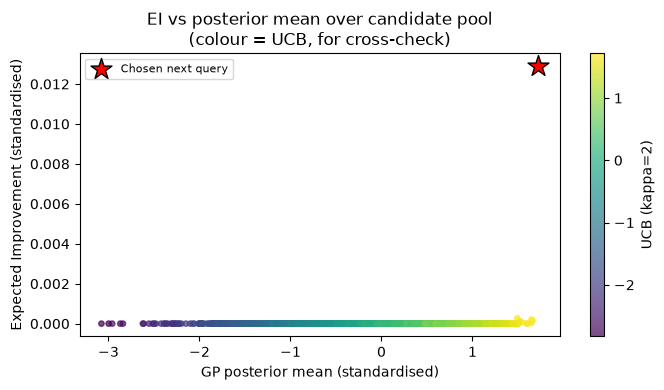

In [8]:
# --------------------------------------------------------------------- #
# OPTIMISE THE ACQUISITION FUNCTION (multi-start, reproducible)
# --------------------------------------------------------------------- #
# The acquisition surface over [0,1]^8 can be multimodal, so a single
# gradient-based optimiser run can get stuck in a local optimum. We use
# a reproducible multi-start strategy:
#   1. Draw N_STARTS space-filling candidate points with a *seeded*
#      Latin Hypercube Sample (better coverage of 8-D space than uniform
#      random for the same budget).
#   2. Evaluate EI at all candidates, keep the best few as starting
#      points for local refinement.
#   3. Polish each with L-BFGS-B (negated EI, since scipy minimises).
#   4. Return the overall best point found.

N_LHS_CANDIDATES = 2000
N_LOCAL_STARTS = 10

sampler = qmc.LatinHypercube(d=d, seed=RNG_SEED)
lhs_unit = sampler.random(n=N_LHS_CANDIDATES)
candidates = qmc.scale(lhs_unit, bounds[:, 0], bounds[:, 1])

ei_candidates = expected_improvement(candidates, gp, f_best_std)
top_idx = np.argsort(ei_candidates)[::-1][:N_LOCAL_STARTS]

best_x, best_ei = None, -np.inf
for idx in top_idx:
    x0 = candidates[idx]

    def neg_ei(x):
        return -expected_improvement(x.reshape(1, -1), gp, f_best_std)[0]

    res = minimize(
        neg_ei, x0, method="L-BFGS-B",
        bounds=bounds, options={"maxiter": 200}
    )
    if -res.fun > best_ei:
        best_ei = -res.fun
        best_x = res.x

mu_next_s, std_next_s = gp.predict(best_x.reshape(1, -1), return_std=True)
mu_next, std_next = unstandardise(mu_next_s, std_next_s)

print("=" * 100)
print("NEXT SUGGESTED QUERY POINT (maximiser of Expected Improvement)")
print("=" * 100)
for j in range(d):
    print(f"  x{j+1} = {best_x[j]:.6f}")
print(f"Predicted mean  : {mu_next[0]:.6f}")
print(f"Predicted std   : {std_next[0]:.6f}")
print(f"Expected Improvement (standardised units): {best_ei:.6f}")
print(f"Current incumbent best observed y: {y.max():.6f}")
print("=" * 100 + "\n")

fig, axes = plt.subplots(figsize=(7, 4))
ax = axes
mu_cand, std_cand = gp.predict(candidates, return_std=True)
ucb_candidates = upper_confidence_bound(candidates, gp, kappa=2.0)
sc = ax.scatter(mu_cand, ei_candidates, c=ucb_candidates, cmap="viridis", s=15, alpha=0.7)
ax.scatter(mu_next_s, best_ei, color="red", marker="*", s=250,
           edgecolor="black", label="Chosen next query", zorder=5)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("UCB (kappa=2)")
ax.set_xlabel("GP posterior mean (standardised)")
ax.set_ylabel("Expected Improvement (standardised)")
ax.set_title("EI vs posterior mean over candidate pool\n(colour = UCB, for cross-check)")
ax.legend(fontsize=8)
plt.tight_layout()